In [196]:
import pkg_resources
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from azure.ai.ml import MLClient
from azure.identity import DefaultAzureCredential
from azure.core.exceptions import HttpResponseError
import mltable
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score , f1_score , confusion_matrix , PrecisionRecallDisplay , ConfusionMatrixDisplay
from azure.ai.ml.entities import Data
from azure.ai.ml import automl
from azure.ai.ml.constants import AssetTypes
from azure.ai.ml.automl import ClassificationPrimaryMetrics
from azure.ai.ml import Input
from ucimlrepo import fetch_ucirepo
from mltable import DataType
import mlflow
from sklearn.utils.multiclass import type_of_target
import subprocess
import warnings 
warnings.filterwarnings('ignore')

In [197]:
subprocess.run('azd auth login')

CompletedProcess(args='azd auth login', returncode=0)

> Authenticating with Azure Machine Learning Studio

In [198]:
ml_client = MLClient(
    credential = DefaultAzureCredential(),
    subscription_id = "48f83b14-32a8-4911-b629-ea5aead7fb29",
    resource_group_name =  "lm1610-rg",
    workspace_name =  "lm_portfolio"
)

Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


In [199]:
banking_data = fetch_ucirepo(id = 222)

In [200]:
X = banking_data.data.features
Y = banking_data.data.targets

In [201]:
banking_df = pd.concat([X,Y], axis = 1)

In [202]:
banking_df

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN,no


In [203]:
banking_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 7.7 MB


In [204]:
banking_cleaned_df = banking_df.fillna(
    {
        'poutcome' : 'unknown',
        'contact' : 'unknown',
        'job' : 'unknown',
        'education' : 'cannot be determined'
    }
).rename(columns = {
    'y' : 'Subscribed'
})

In [205]:
banking_cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          45211 non-null  str  
 2   marital      45211 non-null  str  
 3   education    45211 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      45211 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     45211 non-null  str  
 16  Subscribed   45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [206]:
X_features = banking_cleaned_df.drop(['Subscribed'], axis = 1)
Y_features = banking_cleaned_df['Subscribed']

In [207]:
X_features_updated = pd.get_dummies(X_features).replace({True : 1, False : 0})

In [208]:
Y_features_updated = Y_features.astype('object') 

In [209]:
model = LogisticRegression()

In [210]:
Y_features.shape

(45211,)

In [211]:
X_train , X_temp , Y_train , Y_temp = train_test_split(X_features_updated,Y_features_updated , test_size = 0.5 , random_state = 45)
X_test ,  X_val , Y_test , Y_val = train_test_split(X_temp, Y_temp , test_size = 0.4 , random_state = 45)

In [212]:
model.fit(X_train,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [213]:
type_of_target(y_train_pred)

'binary'

In [214]:
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)

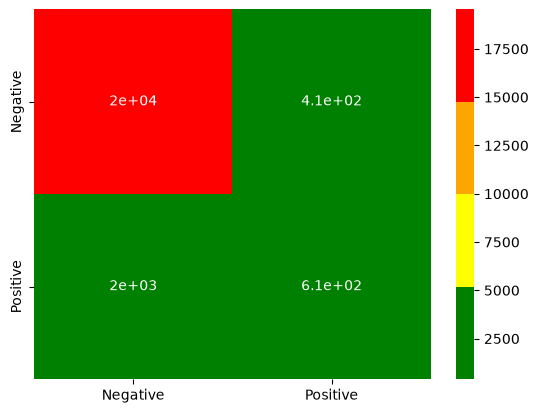

In [215]:
fig = sns.heatmap(
        confusion_matrix(Y_train,y_train_pred), 
        annot = True, 
        yticklabels = ['Negative','Positive'], 
        xticklabels = ['Negative', 'Positive'],
        cmap = ['Green','Yellow','Orange','Red']
        )

In [216]:
y_true = Y_train.replace({'no' : 0, 
    'yes' : 1})

In [217]:
y_score = model.predict_proba(X_train)[:,1]

In [218]:
y_score

array([0.02238014, 0.04748467, 0.01713269, ..., 0.04159401, 0.00514047,
       0.01632253], shape=(22605,))

In [219]:
y_true = pd.to_numeric(y_true)

In [220]:
y_train_pred

array(['no', 'no', 'no', ..., 'no', 'no', 'no'],
      shape=(22605,), dtype=object)

### Integrating MLflow

In [82]:
mlflow.set_tracking_uri('azureml://centralindia.api.azureml.ms/mlflow/v1.0/subscriptions/48f83b14-32a8-4911-b629-ea5aead7fb29/resourceGroups/lm1610-rg/providers/Microsoft.MachineLearningServices/workspaces/lm_portfolio')

In [83]:
mlflow.set_experiment(experiment_name = 'Python code Classification job')

<Experiment: artifact_location='', creation_time=1794831730921, effective_trace_archival_retention=None, experiment_id='7e3c8aaf-801d-4b9f-a3cf-7cf1ed701657', last_update_time=None, lifecycle_stage='active', name='Python code Classification job', tags={}, trace_location=None, workspace='default'>

🏃 View run Logging first MLflow at: https://centralindia.api.azureml.ms/mlflow/v2.0/subscriptions/48f83b14-32a8-4911-b629-ea5aead7fb29/resourceGroups/lm1610-rg/providers/Microsoft.MachineLearningServices/workspaces/lm_portfolio/#/experiments/7e3c8aaf-801d-4b9f-a3cf-7cf1ed701657/runs/ec7f6423-e749-451a-ae5d-6f74a99c59a0
🧪 View experiment at: https://centralindia.api.azureml.ms/mlflow/v2.0/subscriptions/48f83b14-32a8-4911-b629-ea5aead7fb29/resourceGroups/lm1610-rg/providers/Microsoft.MachineLearningServices/workspaces/lm_portfolio/#/experiments/7e3c8aaf-801d-4b9f-a3cf-7cf1ed701657


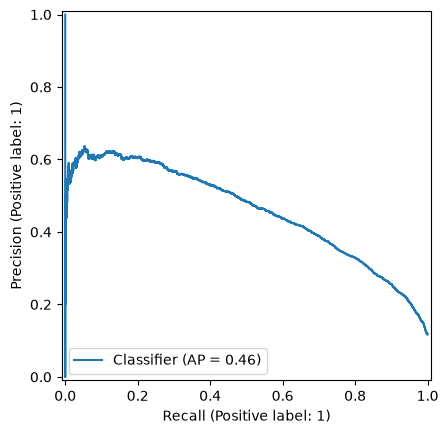

In [227]:
with mlflow.start_run(run_name = 'Logging first MLflow'):
    model = LogisticRegression()
    model.fit(X_train , Y_train)
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)
    training_accuracy = accuracy_score(Y_train,y_train_pred)
    validation_accuracy = accuracy_score(Y_val,y_val_pred)

    mlflow.log_params(
        {
            'Model Used' : model,
            'Training Accuracy' : training_accuracy,
            'Validation Accuracy' : validation_accuracy
        }
    )

    # Plotting the Precision Recall Display
    fig = plt.figure()
    pr_display = PrecisionRecallDisplay.from_predictions(
             y_true,
            y_score ,ax = plt.gca())

    mlflow.log_figure(fig, 'Precision_Recall_Curve.png'

    )

    
    